In [1]:
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

Usando dispositivo: cuda


In [3]:
raw_train = datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
raw_test = datasets.MNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())

In [4]:
pixels = raw_train.data.float() / 255.0
mean = pixels.mean().item()
std = pixels.std().item()
print(f"Média dos pixels: {mean:.4f} | Desvio padrão: {std:.4f}")

Média dos pixels: 0.1307 | Desvio padrão: 0.3081


In [5]:
classes, counts = torch.unique(raw_train.targets, return_counts=True)
print("\nAmostras por classe (Treino):")
for c, count in zip(classes.tolist(), counts.tolist()):
    print(f"Dígito {c}: {count}")


Amostras por classe (Treino):
Dígito 0: 5923
Dígito 1: 6742
Dígito 2: 5958
Dígito 3: 6131
Dígito 4: 5842
Dígito 5: 5421
Dígito 6: 5918
Dígito 7: 6265
Dígito 8: 5851
Dígito 9: 5949


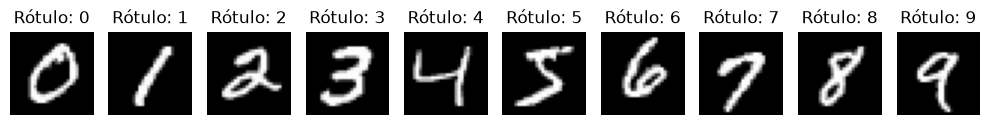

In [6]:
fig, axes = plt.subplots(1, 10, figsize=(10, 2))
for digito in range(10):
    idx = (raw_train.targets == digito).nonzero(as_tuple=True)[0][0]
    img, label = raw_train[idx]

    axes[digito].imshow(img.squeeze(), cmap="gray")
    axes[digito].set_title(f"Rótulo: {label}")
    axes[digito].axis("off")
plt.tight_layout()
plt.show()

In [7]:
from torch.utils.data import DataLoader, random_split

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# carregando dados novamente usando a normalização
full_train = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# separando 50000 para treino e 10000 para validação (seed fixa para reprodutibilidade)
generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset = random_split(full_train, [50000, 10000], generator=generator)

In [8]:
batch_size = 64

# criando dataloaders para treino, validação e teste
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [9]:
import torch.nn as nn

# definindo a arquitetura da rede neural
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Bloco 1: (1, 28, 28) -> (16, 28, 28) -> (16, 14, 14)
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Bloco 2: (16, 14, 14) -> (32, 14, 14) -> (32, 7, 7)
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),                  # 32 * 7 * 7 = 1568
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [10]:
import time
import torch.optim as optim

def train_model(model, train_loader, val_loader, epochs=15, lr=0.01):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    
    train_losses, val_losses = [], []
    start_time = time.time()
    
    for epoch in range(epochs):
        # treinamento
        model.train()
        running_loss = 0.0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * imgs.size(0)
            
        train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(train_loss)
        
        # validação
        model.eval()
        val_running_loss = 0.0
        correct = 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                val_running_loss += loss.item() * imgs.size(0)
                
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                
        val_loss = val_running_loss / len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)
        val_losses.append(val_loss)
        
    total_time = time.time() - start_time
    return train_losses, val_losses, val_acc, total_time

In [11]:
# treinando a CNN com as mesmas configurações da MLP
torch.manual_seed(42)
cnn_model = SimpleCNN().to(device)
cnn_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)

In [12]:
cnn_train_loss, cnn_val_loss, cnn_val_acc, cnn_time = train_model(
    cnn_model, train_loader, val_loader, epochs=15, lr=0.01
)

print(f"SimpleCNN | Params: {cnn_params:,} | Val Loss: {cnn_val_loss[-1]:.4f} | Val Acc: {cnn_val_acc*100:.2f}% | Time: {cnn_time:.1f}s")

SimpleCNN | Params: 206,922 | Val Loss: 0.0506 | Val Acc: 98.46% | Time: 186.5s


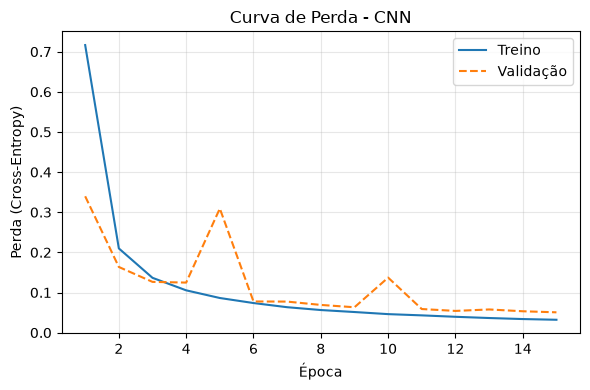

In [14]:
# gráfico da curva de perda da CNN
plt.figure(figsize=(6, 4))
plt.plot(range(1, 16), cnn_train_loss, label="Treino")
plt.plot(range(1, 16), cnn_val_loss, label="Validação", linestyle="--")
plt.title("Curva de Perda - CNN")
plt.xlabel("Época")
plt.ylabel("Perda (Cross-Entropy)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/cnn_loss_curve.png", dpi=150)
plt.show()

CNN Test Accuracy:  98.67%
CNN Test Precision: 98.66% (macro)
CNN Test Recall:    98.67% (macro)
CNN Test F1-Score:  98.66% (macro)


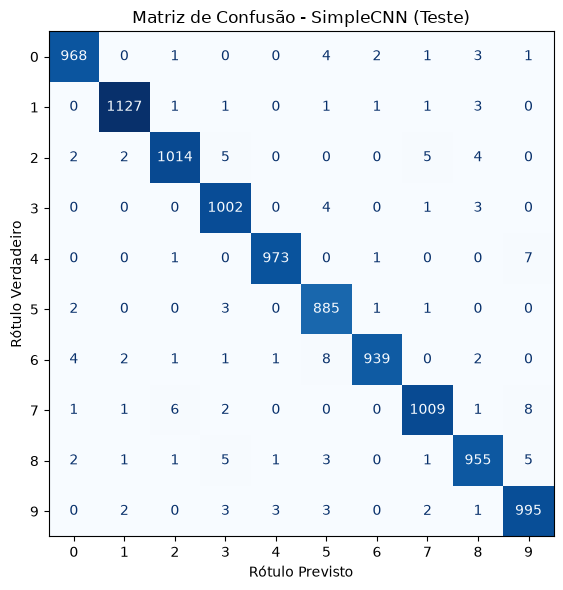


Top 5 confusões da CNN (Real -> Previsto):
Dígito 7 previsto como 9: 8 vezes
Dígito 6 previsto como 5: 8 vezes
Dígito 4 previsto como 9: 7 vezes
Dígito 7 previsto como 2: 6 vezes
Dígito 8 previsto como 3: 5 vezes


In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

cnn_model.eval()
cnn_preds = []
cnn_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = cnn_model(imgs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        
        cnn_preds.extend(preds)
        cnn_labels.extend(labels.numpy())

# Métricas no conjunto de teste
cnn_acc = accuracy_score(cnn_labels, cnn_preds)
cnn_prec = precision_score(cnn_labels, cnn_preds, average="macro")
cnn_rec = recall_score(cnn_labels, cnn_preds, average="macro")
cnn_f1 = f1_score(cnn_labels, cnn_preds, average="macro")

print(f"CNN Test Accuracy:  {cnn_acc*100:.2f}%")
print(f"CNN Test Precision: {cnn_prec*100:.2f}% (macro)")
print(f"CNN Test Recall:    {cnn_rec*100:.2f}% (macro)")
print(f"CNN Test F1-Score:  {cnn_f1*100:.2f}% (macro)")

# Matriz de confusão
cnn_cm = confusion_matrix(cnn_labels, cnn_preds)
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cnn_cm, display_labels=range(10))
disp.plot(cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Matriz de Confusão - SimpleCNN (Teste)")
ax.set_xlabel("Rótulo Previsto")
ax.set_ylabel("Rótulo Verdadeiro")

plt.tight_layout()
plt.savefig("images/cnn_confusion_matrix.png", dpi=150)
plt.show()

# Top 5 confusões
cnn_cm_errors = cnn_cm.copy()
np.fill_diagonal(cnn_cm_errors, 0)
top_cnn_errors = np.dstack(np.unravel_index(np.argsort(cnn_cm_errors.ravel())[::-1], cnn_cm_errors.shape))[0][:5]
print("\nTop 5 confusões da CNN (Real -> Previsto):")
for true_cls, pred_cls in top_cnn_errors:
    print(f"Dígito {true_cls} previsto como {pred_cls}: {cnn_cm_errors[true_cls, pred_cls]} vezes")